# Session 7 — Phase 1 results (read-only record)

Session 7 scored the frozen Phase 1 forecasts against the real actuals. The scoring itself was
done by `scripts/score_phase1.py`, which refuses to run unless:
- the frozen files are byte-identical to tag `phase1-freeze-v1`;
- the learner's predictions were committed first (`notes/phase1_predictions.md`).

**This notebook does not re-score anything.** It reads the saved results in `results/` and shows
them. Sequence of events, all on GitHub:

| Step | Commit |
|---|---|
| Forecast frozen (LightGBM primary; blend and MA4 secondaries) | `1202691`, tag `phase1-freeze-v1` |
| Learner predictions committed (v1, then revised draft) | `14d6731`, `6d1b518` |
| Actuals added and scored | `8abe91f` |
| Analysis, D013 and replacement rules | `08639ae` |

Full account: DECISIONS.md D013. Lessons: `notes/forecasting_playbook.md`.

In [1]:
import os, json, hashlib
from pathlib import Path

current = Path.cwd()
while not (current / "CONTEXT.md").is_file():
    if current == current.parent:
        raise FileNotFoundError("Could not find CONTEXT.md in any parent directory")
    current = current.parent
os.chdir(current)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

scores = pd.read_csv("results/phase1_scores.csv")
weekly = pd.read_csv("results/phase1_weekly_totals.csv", index_col="week", parse_dates=True)
meta = json.loads(Path("results/phase1_scoring.json").read_text())

## 1. Provenance check — the frozen files are still the ones that were scored

In [2]:
sha = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()
for name, expected in meta["frozen_sha256"].items():
    print(f"{name:30s} matches the hash recorded at scoring: {sha(f'submissions/phase1/{name}') == expected}")
print("actuals file:", meta["actuals_file"], "| scored at commit", meta["scored_at_commit"][:7],
      "| predictions commit", meta["predictions_commit"][:7])

phase1_forecast.csv            matches the hash recorded at scoring: True
phase1_secondary_blend.csv     matches the hash recorded at scoring: True
phase1_secondary_ma4.csv       matches the hash recorded at scoring: True
actuals file: Phase 1 - Sales.csv | scored at commit 6d1b518 | predictions commit 6d1b518


## 2. Overall scores (official VN1 metric, lower is better)

In [3]:
overall = scores[scores["slice"] == "all"].sort_values("score").set_index("model")
overall["bias_part"] = overall["bias_pct"].abs()
overall[["score", "mae_pct", "bias_part", "bias_pct", "total_predicted", "total_actual"]].round(4)

,score,mae_pct,bias_part,bias_pct,total_predicted,total_actual
model,,,,,,
Blend (secondary),0.5704,0.5642,0.0062,-0.0062,3.929913e+06,3905806.0
MA4 (secondary),0.6411,0.5420,0.0991,0.0991,3.518681e+06,3905806.0
MA12 (official benchmark),0.6597,0.5420,0.1177,0.1177,3.445926e+06,3905806.0
LightGBM (primary),0.7341,0.6226,0.1115,-0.1115,4.341145e+06,3905806.0


`score = mae_pct + bias_part`. `bias_pct` is signed: positive = under-forecast, negative =
over-forecast. The declared primary (LightGBM) ranked last of the four; the blend kept as a
secondary won, almost entirely on bias (0.6% over). MA4 had the best error part.

## 3. By segment (segments from Phase 0 history)

In [4]:
seg = scores[scores["slice"] != "all"]
print("demand share:", seg.groupby("slice")["demand_share"].first().round(3).to_dict())
seg.pivot(index="slice", columns="model", values="score").round(4)

demand share: {'active': 0.436, 'intermittent': 0.491, 'sparse': 0.073}


model,Blend (secondary),LightGBM (primary),MA12 (official benchmark),MA4 (secondary)
slice,,,,
active,0.5177,0.5730,0.5658,0.5883
intermittent,0.5599,0.7209,0.6639,0.6458
sparse,1.3185,1.7793,1.1894,0.9234


## 4. Weekly shape: actual vs. each forecast

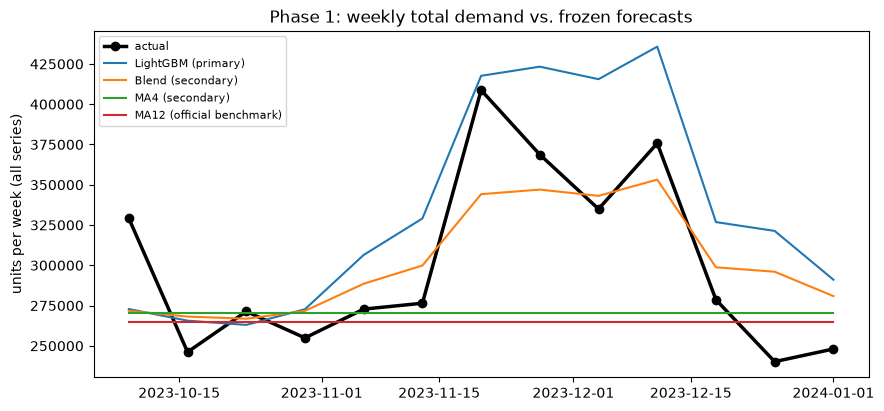

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(weekly.index, weekly["actual"], color="black", linewidth=2.5, marker="o", label="actual")
for col in weekly.columns.drop("actual"):
    ax.plot(weekly.index, weekly[col], linewidth=1.5, label=col)
ax.set_ylabel("units per week (all series)")
ax.set_title("Phase 1: weekly total demand vs. frozen forecasts")
ax.legend(fontsize=8)
plt.show()

In [6]:
(weekly.drop(columns="actual").sub(weekly["actual"], axis=0)).round(0).astype(int).rename(
    columns=lambda c: f"{c} − actual")

,LightGBM (primary) − actual,Blend (secondary) − actual,MA4 (secondary) − actual,MA12 (official benchmark) − actual
week,,,,
2023-10-09,-56314,-57392,-58469,-64066
2023-10-16,19467,21992,24517,18920
2023-10-23,-8360,-4521,-683,-6280
2023-10-30,17811,16775,15740,10143
2023-11-06,33633,15753,-2127,-7724
2023-11-13,52618,23419,-5780,-11377
2023-11-20,8893,-64593,-138078,-143675
2023-11-27,54600,-21723,-98045,-103642
2023-12-04,80594,8155,-64283,-69880


## 5. Size of the rise: forecast vs. actual

Change in total demand against the last 13 Phase 0 weeks (computed from the Phase 0 data).

In [7]:
p0 = pd.read_parquet("data/processed/vn1_long.parquet")
last13 = p0[p0["date"] > p0["date"].unique()[-14]]["sales"].sum()
growth = (weekly.sum() / last13 - 1).rename("change vs last 13 Phase 0 weeks")
growth.map("{:+.1%}".format).to_frame()

,change vs last 13 Phase 0 weeks
actual,+11.3%
LightGBM (primary),+23.7%
Blend (secondary),+12.0%
MA4 (secondary),+0.3%
MA12 (official benchmark),-1.8%


## 6. Prediction vs. outcome

| | Predicted (committed before scoring) | Actual |
|---|---|---|
| 1st | LightGBM | Blend |
| 2nd | Blend | MA4 |
| 3rd | MA4 | MA12 |
| 4th | MA12 | LightGBM |

The learner's interpretation after scoring is in `notes/phase1_predictions.md` ("After scoring").

## What Session 7 established

- **Seasonality was real but weaker.** Demand rose 11%, against 26–37% in earlier years; LightGBM
  forecast +24%, with a peak too broad and running through Christmas.
- **Allocation failed.** LightGBM over-forecast 84% of series and put about 144,000 units on 4,522
  series that sold nothing; MA4 put about 20,500 there.
- **Feature defect.** `lag_52` matched the same week last year only at horizon 1 (see the D013
  correction).
- **Process error.** The pre-written rule picked the blend; a post-hoc analysis on one season
  overrode it. D013 replaces that practice: rules are written first and not overridden.